# DepMap creating

In [45]:
import pandas as pd

effect = pd.read_csv(
    "tools/depmap/CRISPRGeneEffect.csv",
    index_col=0
)

dependency = pd.read_csv(
    "tools/depmap/CRISPRGeneDependency.csv",
    index_col=0
)

models = pd.read_csv("tools/depmap/Model.csv")
common = pd.read_csv(
    "tools/depmap/CRISPRInferredCommonEssentials.csv"
)
print("Gene effect:", effect.shape)
print("Dependency:", dependency.shape)
print("Models:", models.shape)
print(models.columns.tolist())

Gene effect: (1361, 18434)
Dependency: (1361, 18434)
Models: (2554, 48)
['ModelID', 'PatientID', 'CellLineName', 'StrippedCellLineName', 'DepmapModelType', 'OncotreeLineage', 'OncotreePrimaryDisease', 'OncotreeSubtype', 'OncotreeCode', 'RRID', 'Age', 'AgeCategory', 'Sex', 'PatientRace', 'PrimaryOrMetastasis', 'SourceType', 'SourceDetail', 'CatalogNumber', 'SampleCollectionSite', 'ModelSubtypeFeatures', 'PatientSubtypeFeatures', 'TissueOrigin', 'ModelDerivationMaterial', 'ModelTreatment', 'PatientTreatmentStatus', 'PatientTreatmentType', 'PatientTreatmentDetails', 'Stage', 'StagingSystem', 'PatientTumorGrade', 'PatientTreatmentResponse', 'GrowthPattern', 'OnboardedMedia', 'FormulationID', 'SerumFreeMedia', 'PlateCoating', 'EngineeredModel', 'EngineeredModelDetails', 'CulturedResistanceDrug', 'PublicComments', 'CCLEName', 'ModelIDAlias', 'HCMIID', 'ModelType', 'PediatricModelType', 'SangerModelID', 'WTSIMasterCellID', 'COSMICID']


In [46]:
effect.columns = effect.columns.str.replace(
    r"\s+\(\d+\)$", "", regex=True
)

dependency.columns = dependency.columns.str.replace(
    r"\s+\(\d+\)$", "", regex=True
)

In [47]:
myeloid = models[
    models["OncotreeLineage"].astype(str).str.contains(
        "Myeloid",
        case=False,
        na=False
    )
].copy()

print(
    myeloid[
        ["ModelID", "OncotreePrimaryDisease"]
    ].head(20)
)

        ModelID        OncotreePrimaryDisease
1    ACH-000002        Acute Myeloid Leukemia
3    ACH-000004        Acute Myeloid Leukemia
4    ACH-000005        Acute Myeloid Leukemia
5    ACH-000006        Acute Myeloid Leukemia
32   ACH-000034        Acute Myeloid Leukemia
43   ACH-000045        Acute Myeloid Leukemia
63   ACH-000065        Acute Myeloid Leukemia
70   ACH-000072  Myeloproliferative Neoplasms
72   ACH-000074  Myeloproliferative Neoplasms
74   ACH-000076  Myeloproliferative Neoplasms
78   ACH-000080        Acute Myeloid Leukemia
79   ACH-000081        Acute Myeloid Leukemia
82   ACH-000084        Acute Myeloid Leukemia
110  ACH-000112        Acute Myeloid Leukemia
111  ACH-000113        Acute Myeloid Leukemia
144  ACH-000146        Acute Myeloid Leukemia
164  ACH-000166        Acute Myeloid Leukemia
166  ACH-000168        Acute Myeloid Leukemia
188  ACH-000190        Acute Myeloid Leukemia
193  ACH-000195        Acute Myeloid Leukemia


In [58]:
models[models['OncotreePrimaryDisease'].str.contains('fibrosarcoma', case=False, na=False)]

,ModelID,PatientID,CellLineName,StrippedCellLineName,DepmapModelType,OncotreeLineage,OncotreePrimaryDisease,OncotreeSubtype,OncotreeCode,RRID,...,CulturedResistanceDrug,PublicComments,CCLEName,ModelIDAlias,HCMIID,ModelType,PediatricModelType,SangerModelID,WTSIMasterCellID,COSMICID
52,ACH-000054,PT-cVfhmE,HT-1080,HT1080,FIBS,Soft Tissue,Fibrosarcoma,Fibrosarcoma,FIBS,CVCL_0317,...,NaN,NaN,HT1080_SOFT_TISSUE,NaN,NaN,Cell Line,False,SIDM00828,1391.0,907064.0
1755,ACH-002246,PT-CpAxdc,Hs 633.T,HS633T,FIBS,Soft Tissue,Fibrosarcoma,Fibrosarcoma,FIBS,CVCL_0832,...,NaN,NaN,HS633T_SOFT_TISSUE,NaN,NaN,Cell Line,False,SIDM00667,1568.0,1240149.0
1816,ACH-002309,PT-CYTcP8,SW684,SW684,FIBS,Soft Tissue,Fibrosarcoma,Fibrosarcoma,FIBS,CVCL_1726,...,NaN,NaN,SW684_SOFT_TISSUE,NaN,NaN,Cell Line,False,SIDM01175,1559.0,909754.0
2062,ACH-002794,PT-HL3ZQx,NCC-MFS1-C1,NCCMFS1C1,MFS,Soft Tissue,Myxofibrosarcoma,Myxofibrosarcoma,MFS,CVCL_VT41,...,NaN,NaN,NaN,NaN,NaN,Cell Line,False,NaN,NaN,NaN
2065,ACH-002797,PT-nWAnv6,NCC-DFSP1-C1,NCCDFSP1C1,DFSP,Skin,Dermatofibrosarcoma Protuberans,Dermatofibrosarcoma Protuberans,DFSP,CVCL_UR53,...,NaN,NaN,NaN,NaN,NaN,Cell Line,False,NaN,NaN,NaN
2066,ACH-002798,PT-wu6Inf,NCC-DFSP2-C1,NCCDFSP2C1,DFSP,Skin,Dermatofibrosarcoma Protuberans,Dermatofibrosarcoma Protuberans,DFSP,CVCL_UR54,...,NaN,NaN,NaN,NaN,NaN,Cell Line,False,NaN,NaN,NaN
2275,ACH-003172,PT-Ym8fEe,NRH-MFS1,NRHMFS1,MFS,Soft Tissue,Myxofibrosarcoma,Myxofibrosarcoma,MFS,NaN,...,NaN,NaN,NRH-MFS1,NaN,NaN,Cell Line,False,NaN,NaN,NaN
2277,ACH-003174,PT-S2l6Qr,NRH-MFS2,NRHMFS2,MFS,Soft Tissue,Myxofibrosarcoma,Myxofibrosarcoma,MFS,NaN,...,NaN,NaN,NRH-MFS2,NaN,NaN,Cell Line,True,NaN,NaN,NaN
2285,ACH-003183,PT-BqidXH,NRH-MFS3,NRHMFS3,MFS,Soft Tissue,Myxofibrosarcoma,Myxofibrosarcoma,MFS,NaN,...,NaN,NaN,NRH-MFS3,NaN,NaN,Cell Line,False,NaN,NaN,NaN
2294,ACH-003192,PT-1cdRW5,NRH-MFS4,NRHMFS4,MFS,Soft Tissue,Myxofibrosarcoma,Myxofibrosarcoma,MFS,NaN,...,NaN,NaN,NRH-MFS4,NaN,NaN,Cell Line,False,NaN,NaN,NaN


In [22]:
ids = effect.index.intersection(myeloid["ModelID"])

myeloid_effect = effect.loc[ids]

In [23]:
diseases = [
    "Acute Myeloid Leukemia",
    "Myeloproliferative Neoplasms"
]

candidates = models[
    models["OncotreePrimaryDisease"].isin(diseases)
].copy()

cols = [
    "ModelID",
    "CellLineName",
    "OncotreePrimaryDisease",
    "OncotreeSubtype"
]

cols = [c for c in cols if c in candidates.columns]

print("Number of candidate models:", len(candidates))

display(candidates[cols])

Number of candidate models: 89


,ModelID,CellLineName,OncotreePrimaryDisease,OncotreeSubtype
1,ACH-000002,HL-60,Acute Myeloid Leukemia,AML with Myelodysplasia-Related Changes
3,ACH-000004,HEL,Acute Myeloid Leukemia,"AML, NOS"
4,ACH-000005,HEL 92.1.7,Acute Myeloid Leukemia,Acute Myeloid Leukemia
5,ACH-000006,MONO-MAC-6,Acute Myeloid Leukemia,Acute Myeloid Leukemia
32,ACH-000034,PLB-985,Acute Myeloid Leukemia,Acute Myeloid Leukemia
...,...,...,...,...
2147,ACH-002946,UKE-1,Acute Myeloid Leukemia,Acute Myeloid Leukemia
2182,ACH-002994,WSU-AML,Acute Myeloid Leukemia,Acute Myeloid Leukemia
2324,ACH-003273,CHRF-288-11,Acute Myeloid Leukemia,Acute Myeloid Leukemia
2336,ACH-003320,TSU-1621-MT,Acute Myeloid Leukemia,Acute Myeloid Leukemia


In [24]:
import pandas as pd
import numpy as np

# =====================================================
# 1. Select relevant AML models
# =====================================================

selected_subtypes = [
    "Acute Myeloid Leukemia",
    "AML, NOS",
    "Acute Monoblastic/Monocytic Leukemia",
    "AML with Myelodysplasia-Related Changes",
    "Myeloid Leukemia Associated with Down Syndrome"
]

selected_models = models[
    models["OncotreeSubtype"].isin(selected_subtypes)
]

# =====================================================
# 2. Match genes and models
# =====================================================

shared_genes = effect.columns.intersection(
    dependency.columns
)

# Only models present in both matrices
shared_ids = effect.index.intersection(
    dependency.index
)

selected_ids = shared_ids.intersection(
    selected_models["ModelID"]
)

# Background: all other models
other_ids = shared_ids.difference(selected_ids)

E = effect.loc[selected_ids, shared_genes]
P = dependency.loc[selected_ids, shared_genes]

E_other = effect.loc[other_ids, shared_genes]

print("Selected AML models:", len(selected_ids))
print("Background models:", len(other_ids))
print("Genes:", len(shared_genes))

# =====================================================
# 3. Dependency strength
# =====================================================

mean_effect = E.mean(axis=0)
median_effect = E.median(axis=0)

strength = (-mean_effect).clip(lower=0)

# =====================================================
# 4. Dependency prevalence
# =====================================================

fraction_dependent = (
    P.gt(0.5).sum(axis=0) /
    P.notna().sum(axis=0).replace(0, np.nan)
)

# =====================================================
# 5. Selectivity
# =====================================================

other_mean_effect = E_other.mean(axis=0)

# Positive = stronger dependency in AML
selectivity = other_mean_effect - mean_effect

# =====================================================
# 6. Common essential genes
# =====================================================



print(common.head())

# Assumes first column contains gene names
common_essential_genes = set(
    common.iloc[:, 0].astype(str)
    .str.replace(r"\s*\(\d+\)$", "", regex=True)
)

# =====================================================
# 7. Final feature table
# =====================================================

depmap_features = pd.DataFrame({
    "gene": shared_genes,

    "depmap_mean_effect": mean_effect.reindex(
        shared_genes
    ).values,

    "depmap_median_effect": median_effect.reindex(
        shared_genes
    ).values,

    "depmap_strength": strength.reindex(
        shared_genes
    ).values,

    "depmap_fraction_dependent": fraction_dependent.reindex(
        shared_genes
    ).values,

    "depmap_n_models": E.notna().sum(axis=0).reindex(
        shared_genes
    ).values,

    "depmap_effect_sd": E.std(axis=0).reindex(
        shared_genes
    ).values,

    "depmap_other_mean_effect": other_mean_effect.reindex(
        shared_genes
    ).values,

    "depmap_selectivity": selectivity.reindex(
        shared_genes
    ).values
})

# Normalize gene names for integration with DEG
depmap_features["gene"] = (
    depmap_features["gene"]
    .str.replace(r"\s*\(\d+\)$", "", regex=True)
)

depmap_features["common_essential"] = (
    depmap_features["gene"].isin(
        common_essential_genes
    )
)

# =====================================================
# 8. Simple annotation
# =====================================================

depmap_features["selective_dependency"] = (
    (depmap_features["depmap_selectivity"] > 0.3) &
    (depmap_features["depmap_fraction_dependent"] > 0.5)
)

# Sort by strength
depmap_features = depmap_features.sort_values(
    "depmap_strength",
    ascending=False
).reset_index(drop=True)



Selected AML models: 31
Background models: 1330
Genes: 18434
      Essentials
0      AAMP (14)
1     AARS1 (16)
2  AARS2 (57505)
3   ABCE1 (6059)
4     ABCF1 (23)


,gene,depmap_mean_effect,depmap_median_effect,depmap_strength,depmap_fraction_dependent,depmap_n_models,depmap_effect_sd,depmap_other_mean_effect,depmap_selectivity,common_essential,selective_dependency
0,RPL15,-5.641655,-5.641655,5.641655,1.0,2,0.107876,-5.247599,0.394056,True,True
1,SNRPD3,-4.961456,-5.009150,4.961456,1.0,9,0.532820,-4.892784,0.068672,True,False
2,RAN,-4.211602,-4.276280,4.211602,1.0,31,0.542473,-4.083816,0.127785,True,False
3,RPL17,-3.721684,-3.752974,3.721684,1.0,31,0.265691,-3.666825,0.054859,True,False
4,HSPE1,-3.691372,-3.717767,3.691372,1.0,27,0.386286,-3.678182,0.013190,True,False


In [34]:
depmap_features.head()

,gene,depmap_mean_effect,depmap_median_effect,depmap_strength,depmap_fraction_dependent,depmap_n_models,depmap_effect_sd,depmap_other_mean_effect,depmap_selectivity,common_essential,selective_dependency
0,RPL15,-5.641655,-5.641655,5.641655,1.0,2,0.107876,-5.247599,0.394056,True,True
1,SNRPD3,-4.961456,-5.009150,4.961456,1.0,9,0.532820,-4.892784,0.068672,True,False
2,RAN,-4.211602,-4.276280,4.211602,1.0,31,0.542473,-4.083816,0.127785,True,False
3,RPL17,-3.721684,-3.752974,3.721684,1.0,31,0.265691,-3.666825,0.054859,True,False
4,HSPE1,-3.691372,-3.717767,3.691372,1.0,27,0.386286,-3.678182,0.013190,True,False


In [35]:
depmap_features.to_csv('depmap_features.csv')

# DepMap test

In [31]:
deg = pd.read_csv('data/CD14_Mono_DEGs_Masha.csv', header=0, names=['gene', 'baseMean', 'log2FC', 'lfcSE', 'stat', 'pvalue', 'padj'])

In [39]:
depmap_features=pd.read_csv('tools/depmap/depmap_features.csv')

In [41]:
depmap_features['depmap_strength']

0        5.641655
1        4.961456
2        4.211602
3        3.721684
4        3.691372
           ...   
18429    0.000000
18430    0.000000
18431    0.000000
18432    0.000000
18433    0.000000
Name: depmap_strength, Length: 18434, dtype: float64

In [43]:
required = ["gene", "depmap_strength", "depmap_fraction_dependent", "depmap_selectivity"]
missing = [col for col in required if col not in depmap_features.columns]

In [44]:
missing

[]

In [34]:
# Приводим названия генов к одному формату
deg["gene"] = deg["gene"].astype(str).str.strip()
depmap_features["gene"] = (
    depmap_features["gene"].astype(str).str.strip()
)

# Добавляем DepMap-метрики к DEG
deg_depmap = deg.merge(
    depmap_features,
    on="gene",
    how="left",
    validate="many_to_one"
)

print("Total DEG:", len(deg))
print("Matched:", deg_depmap["depmap_mean_effect"].notna().sum())
print("Not matched:", deg_depmap["depmap_mean_effect"].isna().sum())

Total DEG: 2138
Matched: 1783
Not matched: 355


In [35]:
candidates = deg_depmap[
    (deg_depmap["depmap_strength"] > 0.5) &
    (deg_depmap["depmap_fraction_dependent"] > 0.5) &
    (deg_depmap["depmap_selectivity"] > 0)
].copy()

candidates = candidates.sort_values(
    "depmap_strength",
    ascending=False
)

print("Candidates:", len(candidates))

display(candidates[[
    "gene",
    "depmap_strength",
    "depmap_fraction_dependent",
    "depmap_selectivity",
    "common_essential"
]].head(30))

Candidates: 114


,gene,depmap_strength,depmap_fraction_dependent,depmap_selectivity,common_essential
930,PSMB3,3.028933,1.000000,0.042998,True
106,PCNA,3.006287,1.000000,0.038871,True
167,SF3B5,2.882808,1.000000,0.181599,True
607,SS18L2,2.775809,1.000000,0.220602,True
1847,GINS2,2.700962,1.000000,0.163774,True
1093,EEF1A1,2.688179,1.000000,0.261057,True
495,LSM2,2.658489,1.000000,0.010573,True
995,SPC24,2.625157,1.000000,0.011468,True
1893,DONSON,2.583991,1.000000,0.196855,True
1194,CDC27,2.563153,1.000000,0.123992,True


In [37]:
deg_depmap.sort_values(
    ["common_essential", "depmap_strength"],
    ascending=[True, False],
    na_position="last"
)[[
    "gene",
    "depmap_strength",
    "depmap_fraction_dependent",
    "depmap_selectivity",
    "common_essential"
]].head(5)

,gene,depmap_strength,depmap_fraction_dependent,depmap_selectivity,common_essential
1525,CBFB,1.259513,0.967742,1.069522,False
639,GPX4,1.041228,0.935484,0.461166,False
907,CMIP,0.828891,0.677419,0.502565,False
843,ZEB2,0.789318,0.709677,0.497116,False
868,RCOR1,0.680290,0.645161,0.305114,False


# Load Dataset

In [4]:
import scanpy as sc

In [7]:
adata = sc.read_h5ad(f"data/dataset.h5ad")
adata.obs["sample_groups_wide"] = adata.obs["sample_groups"].map({
    "PTPN11": "JMML",
    "NF1" :"JMML",
    "NRAS":"JMML",
    "KRAS":"JMML",
    "RALD":"RALD",
    "CBL":"JMML",
    "Control": "Control",
    #"Control2": "control",
    #"Control3": "control"
})

/home/mbelyakov/.conda/envs/jmml_targets/lib/python3.11/site-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


# CollectrI

In [8]:
import decoupler as dc
import pandas as pd
import numpy as np
import scipy.sparse as sp

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

collectri = dc.op.collectri(
    organism="human",
    remove_complexes=True
)

print("Interactions:", len(collectri))
print("Transcription factors:", collectri["source"].nunique())
print("Target genes:", collectri["target"].nunique())

display(collectri.head())

Interactions: 41595
Transcription factors: 1183
Target genes: 6616


,source,target,weight,resources,references,sign_decision
0,MYC,TERT,1.0,DoRothEA-A;ExTRI;HTRI;NTNU.Curated;Pavlidis202...,10022128;10491298;10606235;10637317;10723141;1...,PMID
1,SPI1,BGLAP,1.0,ExTRI,10022617,default activation
2,SMAD3,JUN,1.0,ExTRI;NTNU.Curated;TFactS;TRRUST,10022869;12374795,PMID
3,SMAD4,JUN,1.0,ExTRI;NTNU.Curated;TFactS;TRRUST,10022869;12374795,PMID
4,STAT5A,IL2,1.0,ExTRI,10022878;11435608;17182565;17911616;22854263;2...,default activation


In [9]:
keep_groups = ["jmml", "control"]
keep_celltypes = ["hsc", "gmp", "cd14 mono"]

group_col = "sample_groups_wide"
celltype_col = "celltype_l2_merged_rename"
sample_col = "batch"

groups = (
    adata.obs[group_col]
    .astype("string")
    .str.strip()
    .str.lower()
)

celltypes = (
    adata.obs[celltype_col]
    .astype("string")
    .str.strip()
    .str.lower()
)

mask = (
    groups.isin(keep_groups)
    & celltypes.isin(keep_celltypes)
).fillna(False).to_numpy()

cell_idx = np.flatnonzero(mask)

print(f"Selected cells: {len(cell_idx)} / {adata.n_obs}")

Selected cells: 15386 / 91927


In [10]:
group_cols = [
    sample_col,
    group_col,
    celltype_col
]

meta = (
    adata.obs.iloc[cell_idx][group_cols]
    .copy()
    .reset_index(drop=True)
)

meta[group_col] = groups.iloc[cell_idx].to_numpy()
meta[celltype_col] = celltypes.iloc[cell_idx].to_numpy()

meta = meta.astype("string").fillna("Unknown")

meta["gid"] = meta.groupby(
    group_cols,
    sort=True
).ngroup()

group_info = (
    meta.drop_duplicates("gid")[["gid"] + group_cols]
    .sort_values("gid")
    .reset_index(drop=True)
)

group_codes = meta["gid"].to_numpy()
n_groups = len(group_info)

n_cells = np.bincount(
    group_codes,
    minlength=n_groups
)

print("Number of profiles:", n_groups)

display(
    meta.groupby(
        [group_col, celltype_col]
    ).size().reset_index(name="n_cells")
)

Number of profiles: 48


,sample_groups_wide,celltype_l2_merged_rename,n_cells
0,control,cd14 mono,1056
1,control,gmp,235
2,control,hsc,104
3,jmml,cd14 mono,10793
4,jmml,gmp,1320
5,jmml,hsc,1878


In [11]:
network_targets = set(collectri["target"])

available_targets = (
    adata.var_names.isin(network_targets)
)

print(
    "CollecTRI targets available:",
    available_targets.sum(),
    "/",
    collectri["target"].nunique()
)

tf_coverage = (
    collectri.assign(
        present=collectri["target"].isin(adata.var_names)
    )
    .groupby("source")
    .agg(
        total_targets=("target", "nunique"),
        available_targets=("present", "sum")
    )
)

tf_coverage["coverage"] = (
    tf_coverage["available_targets"]
    / tf_coverage["total_targets"]
)

display(
    tf_coverage.sort_values(
        "available_targets",
        ascending=False
    ).head(20)
)

CollecTRI targets available: 6495 / 6616


,total_targets,available_targets,coverage
source,,,
SP1,1304,1292,0.990798
TP53,980,961,0.980612
MYC,887,873,0.984216
JUN,662,654,0.987915
ESR1,634,624,0.984227
RELA,560,556,0.992857
AR,514,507,0.986381
HIF1A,463,460,0.993521
CREB1,464,459,0.989224


In [12]:
n_genes = adata.n_vars

sums = np.zeros(
    (n_groups, n_genes),
    dtype=np.float64
)

batch_size = 256

for start in range(0, len(cell_idx), batch_size):

    end = min(start + batch_size, len(cell_idx))
    idx = cell_idx[start:end]

    # Counts: cells × all genes
    X = adata.layers["counts"][idx, :]

    if not sp.issparse(X):
        X = sp.csr_matrix(X)
    else:
        X = X.tocsr(copy=True)

    X = X.astype(np.float32)

    # Total counts per cell
    library_sizes = np.asarray(
        X.sum(axis=1)
    ).ravel()

    # Normalize to 10,000 counts
    scale = (
        1e4 / np.maximum(library_sizes, 1)
    )

    X = sp.diags(scale) @ X

    # log1p
    X.data = np.log1p(X.data)

    # Sum expression within each group
    # Sparse group aggregation avoids dense cells × genes
    local_codes = group_codes[start:end]

    membership = sp.csr_matrix(
        (
            np.ones(len(local_codes), dtype=np.float32),
            (local_codes, np.arange(len(local_codes)))
        ),
        shape=(n_groups, len(local_codes))
    )

    sums += (membership @ X).toarray()

    if start % 12800 == 0:
        print(f"Processed {end}/{len(cell_idx)}")

profiles = pd.DataFrame(
    sums / n_cells[:, None],
    index=[f"G{i}" for i in range(n_groups)],
    columns=adata.var_names
)

group_info["group_id"] = profiles.index
group_info["n_cells"] = n_cells

print("Profiles:", profiles.shape)
print("Nonzero:", np.count_nonzero(profiles.to_numpy()))

display(group_info.head())

Processed 256/15386
Processed 13056/15386
Profiles: (48, 39825)
Nonzero: 616881


,gid,batch,sample_groups_wide,celltype_l2_merged_rename,group_id,n_cells
0,0,CBL,jmml,cd14 mono,G0,1981
1,1,CBL,jmml,gmp,G1,387
2,2,CBL,jmml,hsc,G2,284
3,3,KRAS,jmml,cd14 mono,G3,1456
4,4,KRAS,jmml,gmp,G4,175


In [16]:
tf_scores, tf_pvals = dc.mt.ulm(
    data=profiles,
    net=collectri,
    tmin=5
)

print("TF activity matrix:", tf_scores.shape)

display(tf_scores.iloc[:5, :10])

TF activity matrix: (48, 727)


,ABL1,AEBP1,AHR,AIP,AIRE,APEX1,AR,ARID1A,ARID1B,ARID3A
G0,1.377729,2.010167,4.992138,1.720080,5.447563,2.570096,14.461976,1.246975,0.375595,0.025879
G1,0.927797,0.192582,5.256401,0.873978,3.760570,2.740579,15.028836,0.535197,0.338132,0.963624
G2,1.839859,-0.560430,5.018341,-0.742799,2.129470,2.795091,15.058397,0.790380,0.121628,-0.172693
G3,4.589381,0.723152,4.833237,0.489609,6.621170,3.284474,14.708771,1.537888,0.047157,-0.030079
G4,3.054867,-0.015086,4.833973,0.449037,4.467657,3.203885,13.386810,0.588417,0.123455,0.694013


In [17]:
tf_results = pd.concat(
    [
        group_info.reset_index(drop=True),
        tf_scores.reset_index(drop=True)
    ],
    axis=1
)

display(tf_results.head())

,gid,batch,sample_groups_wide,celltype_l2_merged_rename,group_id,n_cells,ABL1,AEBP1,AHR,AIP,...,ZNF382,ZNF384,ZNF395,ZNF410,ZNF436,ZNF699,ZNF76,ZNF804A,ZNF91,ZXDC
0,0,CBL,jmml,cd14 mono,G0,1981,1.377729,2.010167,4.992138,1.720080,...,-2.711244,-1.105502,0.920118,0.624813,1.556789,1.781410,1.668022,1.208986,5.310196,2.097137
1,1,CBL,jmml,gmp,G1,387,0.927797,0.192582,5.256401,0.873978,...,-3.597670,-1.754490,0.642617,0.727644,2.033523,2.818178,1.941963,0.405378,3.219653,0.681683
2,2,CBL,jmml,hsc,G2,284,1.839859,-0.560430,5.018341,-0.742799,...,-6.160189,-2.197862,0.846348,1.033736,2.610791,3.604112,1.989757,-0.051081,2.685855,1.508868
3,3,KRAS,jmml,cd14 mono,G3,1456,4.589381,0.723152,4.833237,0.489609,...,-4.635860,-0.377242,0.277443,0.261631,1.057307,2.263571,1.893054,1.833941,3.771310,1.942054
4,4,KRAS,jmml,gmp,G4,175,3.054867,-0.015086,4.833973,0.449037,...,-3.809958,-0.805448,0.522591,0.104685,1.417728,2.627135,2.402067,1.261797,2.235278,0.907425


In [18]:
from pathlib import Path

outdir = Path("output/collecrti_results/")
outdir.mkdir(parents=True, exist_ok=True)

collectri = dc.op.collectri(
    organism="human",
    remove_complexes=True
)

tf_scores, tf_pvals = dc.mt.ulm(
    data=profiles,
    net=collectri,
    tmin=5
)

tf_activity = tf_scores.copy()

tf_activity.index.name = "group_id"

# Добавляем метаданные
tf_activity = (
    group_info
    .set_index("group_id")
    .join(tf_activity)
    .reset_index()
)

tf_activity.to_csv(
    outdir / "tf_activity.csv",
    index=False
)

# Сохраняем экспрессионные профили и сеть
profiles.to_csv(outdir / "expression_profiles.csv")

collectri.to_csv(
    outdir / "collectri_network.csv",
    index=False
)

In [21]:
tf_names = tf_scores.columns.tolist()

tf_long = tf_activity.melt(
    id_vars=[
        "group_id",
        sample_col,
        group_col,
        celltype_col,
        "n_cells"
    ],
    value_vars=tf_names,
    var_name="gene",
    value_name="activity"
)

tf_summary = (
    tf_long
    .groupby(
        [celltype_col, group_col, "gene"],
        observed=True
    )
    .agg(
        mean_activity=("activity", "mean"),
        n_samples=("activity", "count")
    )
    .reset_index()
)

tf_wide = tf_summary.pivot(
    index=[celltype_col, "gene"],
    columns=group_col,
    values="mean_activity"
).reset_index()

tf_wide["delta_activity"] = (
    tf_wide["jmml"] - tf_wide["control"]
)

tf_wide.to_csv(
    outdir / "tf_activity_summary.csv",
    index=False
)

In [23]:
deg = pd.read_csv("data/CD14_Mono_candidates_GTEx_v11.csv")

tf_wide = pd.read_csv(
    f"{outdir}/tf_activity_summary.csv"
)

tf_wide = tf_wide.rename(
    columns={celltype_col: "celltype"}
)

deg["gene"] = deg["gene"].astype(str).str.strip()
deg["celltype"] = "CD14 Mono"
tf_wide["celltype"] = (
    tf_wide["celltype"].astype(str).str.strip().str.lower()
)

# Оставляем только DEG, которые представлены среди TF
candidate_tf = deg.merge(
    tf_wide[
        ["celltype", "gene", "jmml", "control", "delta_activity"]
    ],
    on=["celltype", "gene"],
    how="inner",
    validate="many_to_one"
)

candidate_tf.to_csv(
    "results/collectri/candidate_tf.csv",
    index=False
)

display(candidate_tf.head(20))

,gene,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,DE_status,HPA_symbol,HPA_PM_or_CJ,...,GTEx_max_tissue,GTEx_match,Tumor_specific,GTEx_version,Candidate,Atlases,celltype,jmml,control,delta_activity


In [26]:
celltype_col = "celltype_l2_merged_rename"
adata.obs[celltype_col].value_counts()

celltype_l2_merged_rename
CD14 Mono             12727
Memory B               7440
transitional B         6503
CD16 Mono              6337
Late Eryth             4977
CD4 T cells            4540
Pre B                  4512
Classical monocyte     4326
NK                     3272
Pro B                  3235
CD8 T cells            3087
HSC/MPP                2142
Naive/Memory B         2049
HSC                    2011
Myelocyte              1880
pDC                    1832
EryP                   1658
Naive B                1646
GMP                    1626
Pro B cycling          1518
Early Eryth            1342
cDC2                   1291
CD4 Naive               980
MEP                     958
Naive T                 929
LMPP                    759
Pro myelocyte           674
Pre B cycling           654
pre B                   626
Memory T                599
Prog DC/cDC             576
CLP                     498
EMP                     485
LyP                     464
MAIT                  

TF activity matrix: (48, 727)


,ABL1,AEBP1,AHR,AIP,AIRE,APEX1,AR,ARID1A,ARID1B,ARID3A
G0,1.377729,2.010167,4.992138,1.720080,5.447563,2.570096,14.461976,1.246975,0.375595,0.025879
G1,0.927797,0.192582,5.256401,0.873978,3.760570,2.740579,15.028836,0.535197,0.338132,0.963624
G2,1.839859,-0.560430,5.018341,-0.742799,2.129470,2.795091,15.058397,0.790380,0.121628,-0.172693
G3,4.589381,0.723152,4.833237,0.489609,6.621170,3.284474,14.708771,1.537888,0.047157,-0.030079
G4,3.054867,-0.015086,4.833973,0.449037,4.467657,3.203885,13.386810,0.588417,0.123455,0.694013


,gid,batch,sample_groups_wide,celltype_l2_merged_rename,group_id,n_cells,ABL1,AEBP1,AHR,AIP,...,ZNF382,ZNF384,ZNF395,ZNF410,ZNF436,ZNF699,ZNF76,ZNF804A,ZNF91,ZXDC
0,0,CBL,jmml,cd14 mono,G0,1981,1.377729,2.010167,4.992138,1.720080,...,-2.711244,-1.105502,0.920118,0.624813,1.556789,1.781410,1.668022,1.208986,5.310196,2.097137
1,1,CBL,jmml,gmp,G1,387,0.927797,0.192582,5.256401,0.873978,...,-3.597670,-1.754490,0.642617,0.727644,2.033523,2.818178,1.941963,0.405378,3.219653,0.681683
2,2,CBL,jmml,hsc,G2,284,1.839859,-0.560430,5.018341,-0.742799,...,-6.160189,-2.197862,0.846348,1.033736,2.610791,3.604112,1.989757,-0.051081,2.685855,1.508868
3,3,KRAS,jmml,cd14 mono,G3,1456,4.589381,0.723152,4.833237,0.489609,...,-4.635860,-0.377242,0.277443,0.261631,1.057307,2.263571,1.893054,1.833941,3.771310,1.942054
4,4,KRAS,jmml,gmp,G4,175,3.054867,-0.015086,4.833973,0.449037,...,-3.809958,-0.805448,0.522591,0.104685,1.417728,2.627135,2.402067,1.261797,2.235278,0.907425


In [19]:
results = []

tf_genes = tf_scores.columns.tolist()

for ct in keep_celltypes:

    sub = tf_results[
        tf_results[celltype_col] == ct
    ]

    for tf in tf_genes:

        jmml = (
            sub.loc[sub[group_col] == "jmml", tf]
            .dropna()
            .to_numpy(dtype=float)
        )

        ctrl = (
            sub.loc[sub[group_col] == "control", tf]
            .dropna()
            .to_numpy(dtype=float)
        )

        if len(jmml) < 2 or len(ctrl) < 2:
            continue

        _, pval = mannwhitneyu(
            jmml,
            ctrl,
            alternative="two-sided"
        )

        results.append({
            "celltype": ct,
            "gene": tf,
            "n_jmml": len(jmml),
            "n_control": len(ctrl),
            "mean_jmml": np.mean(jmml),
            "mean_control": np.mean(ctrl),
            "delta_activity": np.mean(jmml) - np.mean(ctrl),
            "pvalue": pval
        })

diff_tf = pd.DataFrame(results)

if diff_tf.empty:
    raise ValueError("Not enough samples to compare JMML and Control.")

diff_tf["padj"] = (
    diff_tf.groupby("celltype")["pvalue"]
    .transform(
        lambda x: multipletests(
            x,
            method="fdr_bh"
        )[1]
    )
)

diff_tf["abs_delta"] = (
    diff_tf["delta_activity"].abs()
)

diff_tf = diff_tf.sort_values(
    ["celltype", "padj", "abs_delta"],
    ascending=[True, True, False]
)

display(diff_tf.head(30))

,celltype,gene,n_jmml,n_control,mean_jmml,mean_control,delta_activity,pvalue,padj,abs_delta
2014,cd14 mono,SMARCA4,8,9,-3.342665,-5.883106,2.540441,0.000082,0.002215,2.540441
1965,cd14 mono,RB1,8,9,1.114831,-1.292296,2.407126,0.000082,0.002215,2.407126
1830,cd14 mono,NCOA1,8,9,3.038719,0.785946,2.252773,0.000082,0.002215,2.252773
1756,cd14 mono,KLF5,8,9,3.878371,1.691089,2.187282,0.000082,0.002215,2.187282
2123,cd14 mono,VHL,8,9,-4.951356,-2.799767,-2.151589,0.000082,0.002215,2.151589
1657,cd14 mono,HDAC9,8,9,-4.476865,-2.330695,-2.146170,0.000082,0.002215,2.146170
2140,cd14 mono,ZBTB7A,8,9,1.642467,-0.256393,1.898861,0.000082,0.002215,1.898861
1950,cd14 mono,PPARG,8,9,3.235766,1.462880,1.772886,0.000082,0.002215,1.772886
2083,cd14 mono,TEAD4,8,9,2.851721,1.081146,1.770575,0.000082,0.002215,1.770575
1710,cd14 mono,ID1,8,9,2.144749,0.409147,1.735601,0.000082,0.002215,1.735601


In [20]:
candidate_genes = pd.read_csv('data/CD14_Mono_DEGs_Masha.csv', header=0, names=['gene', 'baseMean', 'log2FC', 'lfcSE', 'stat', 'pvalue', 'padj'])

In [26]:
candidate_genes=candidate_genes.to_list()

In [28]:
candidate_tf = diff_tf[
    diff_tf["gene"].isin(candidate_genes)
].copy()

display(
    candidate_tf.sort_values(
        ["padj", "abs_delta"],
        ascending=[True, False]
    )
)

,celltype,gene,n_jmml,n_control,mean_jmml,mean_control,delta_activity,pvalue,padj,abs_delta
2140,cd14 mono,ZBTB7A,8,9,1.642467,-0.256393,1.898861,0.000082,0.002215,1.898861
2043,cd14 mono,SREBF2,8,9,1.583230,0.551978,1.031252,0.000082,0.002215,1.031252
1859,cd14 mono,NFX1,8,9,0.938993,-1.571729,2.510722,0.000329,0.003681,2.510722
1834,cd14 mono,NCOR2,8,9,2.369171,0.658835,1.710337,0.000329,0.003681,1.710337
1833,cd14 mono,NCOR1,8,9,4.277643,2.407047,1.870596,0.000576,0.005233,1.870596
...,...,...,...,...,...,...,...,...,...,...
1201,gmp,PIN1,8,8,0.371256,0.637480,-0.266224,0.959130,0.975227,0.266224
1320,gmp,SSRP1,8,8,3.938628,4.006285,-0.067657,0.959130,0.975227,0.067657
844,gmp,EP300,8,8,1.689269,1.633588,0.055680,1.000000,1.000000,0.055680
2007,cd14 mono,SMAD3,8,9,2.860199,2.841743,0.018456,1.000000,1.000000,0.018456


In [29]:
from pathlib import Path

outdir = Path("results/collectri")
outdir.mkdir(parents=True, exist_ok=True)

tf_results.to_csv(
    outdir / "tf_activity_by_sample.csv",
    index=False
)

diff_tf.to_csv(
    outdir / "differential_tf_activity.csv",
    index=False
)

candidate_tf.to_csv(
    outdir / "candidate_tf_activity.csv",
    index=False
)

tf_coverage.to_csv(
    outdir / "tf_network_coverage.csv"
)

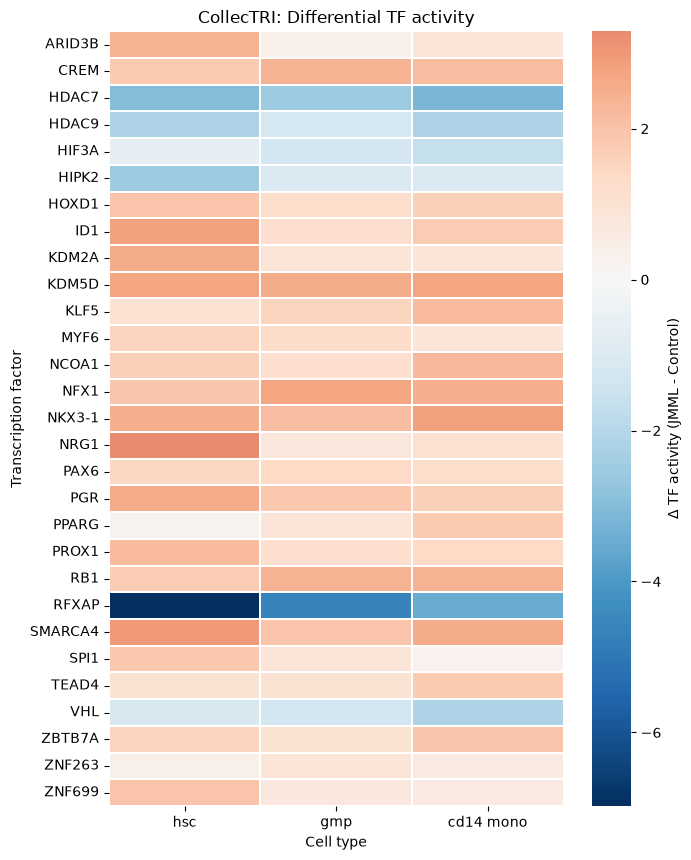

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

# Top 10 TF per celltype by adjusted p-value
top_genes = (
    diff_tf.sort_values(
        ["padj", "abs_delta"],
        ascending=[True, False]
    )
    .groupby("celltype")
    .head(10)["gene"]
    .unique()
)

heatmap_data = (
    diff_tf[
        diff_tf["gene"].isin(top_genes)
    ]
    .pivot(
        index="gene",
        columns="celltype",
        values="delta_activity"
    )
    .reindex(columns=keep_celltypes)
)

plt.figure(
    figsize=(7, max(6, len(top_genes) * 0.3))
)

sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=0,
    linewidths=0.3,
    cbar_kws={
        "label": "Δ TF activity (JMML - Control)"
    }
)

plt.title("CollecTRI: Differential TF activity")
plt.xlabel("Cell type")
plt.ylabel("Transcription factor")
plt.tight_layout()
plt.show()

# Test DEG

In [15]:
import pandas as pd
import numpy as np
import decoupler as dc

deg = pd.read_csv("data/GMP_JMML_vs_Control.csv", names = ['gene', 'baseMean', 'log2FC', 'lfcSE', 'stat', 'pvalue', 'padj'], header=0)

print(deg.shape)
print(deg.columns.tolist())
display(deg.head())

FileNotFoundError: [Errno 2] No such file or directory: 'data/GMP_JMML_vs_Control.csv'

In [71]:
# Один клеточный тип, например HSC
de_gmp = deg.copy()

# Оставляем уникальные гены
de_gmp = de_gmp.dropna(subset=["gene", "stat"])
de_gmp = de_gmp.drop_duplicates("gene")

# Одна строка = одно сравнение, столбцы = гены
de_matrix = pd.DataFrame(
    [de_gmp.set_index("gene")["stat"]],
    index=["GMP_JMML_vs_Control"]
)

# Используем PROGENy footprint
network = progeny[["source", "target", "weight"]]

scores, pvals = dc.mt.ulm(
    data=de_matrix,
    net=network,
    tmin=5
)

display(scores.T.sort_values(
    "GMP_JMML_vs_Control",
    ascending=False
))

,GMP_JMML_vs_Control
PI3K,4.445387
Hypoxia,2.770832
VEGF,2.297708
Androgen,1.715831
TGFb,1.562725
MAPK,1.139685
NFkB,1.131632
Estrogen,0.219737
Trail,-0.197828
TNFa,-0.264219


In [72]:
deg

,gene,baseMean,log2FC,lfcSE,stat,pvalue,padj
0,MINOS1,81.556864,-11.471453,1.042071,-11.008325,3.484211e-28,3.056002e-24
1,FKBP2,41.215592,-5.415920,0.573207,-9.448462,3.438463e-21,1.507938e-17
2,UQCRHL,46.443325,-6.711289,0.719834,-9.323379,1.126930e-20,3.294769e-17
3,FNDC3B,439.436055,3.816017,0.417585,9.138301,6.344116e-20,1.391106e-16
4,ALDOA,131.908112,-5.245401,0.580487,-9.036203,1.622078e-19,2.845449e-16
...,...,...,...,...,...,...,...
9506,ZNRF3,5.142774,1.506506,0.997126,1.510848,1.308272e-01,NaN
9507,ZSCAN12,2.040089,2.215455,1.650452,1.342333,1.794882e-01,NaN
9508,ZSCAN29,5.045797,-0.931436,0.691651,-1.346686,1.780815e-01,NaN
9509,ZSWIM4,5.152785,1.361130,0.998004,1.363852,1.726140e-01,NaN


In [73]:
depmap_features = pd.read_csv('depmap_features.csv')
deg_depmap = deg.merge(
    depmap_features,
    on="gene",
    how="left"
)

display(
    deg_depmap[
        [
            "gene",
            "log2FC",
            "padj",
            "depmap_mean_effect",
            "depmap_fraction_dependent",
            "depmap_selectivity"
        ]
    ].head(20)
)

,gene,log2FC,padj,depmap_mean_effect,depmap_fraction_dependent,depmap_selectivity
0,MINOS1,-11.471453,3.056002e-24,NaN,NaN,NaN
1,FKBP2,-5.415920,1.507938e-17,-0.001740,0.000000,-0.030398
2,UQCRHL,-6.711289,3.294769e-17,0.201478,0.000000,-0.087084
3,FNDC3B,3.816017,1.391106e-16,-0.039125,0.000000,-0.020139
4,ALDOA,-5.245401,2.845449e-16,-1.385526,1.000000,-0.084310
5,MED13L,3.914749,1.364642e-14,-0.407288,0.419355,0.276265
6,ZFAND3,5.809077,1.364642e-14,-0.143370,0.032258,0.023675
7,PLCB1,5.487822,3.019756e-14,0.121886,0.000000,-0.000585
8,CHST11,3.538553,9.399445e-14,-0.061080,0.000000,-0.005522
9,SIK3,5.217580,1.744649e-13,-0.227681,0.193548,0.272403


In [76]:
pg_features = (
    progeny.groupby("target")
    .agg(
        progeny_n_pathways=("source", "nunique"),
        progeny_max_abs_weight=("weight", lambda x: x.abs().max())
    )
    .reset_index()
    .rename(columns={"target": "gene"})
)

features = deg_depmap.merge(
    pg_features,
    on="gene",
    how="left"
)

features.to_csv(
    "JMML_DEG_DepMap_PROGENy_GMP.csv",
    index=False
)

In [77]:
features

,gene,baseMean,log2FC,lfcSE,stat,pvalue,padj,Unnamed: 0,depmap_mean_effect,depmap_median_effect,depmap_fraction_dependent,depmap_n_models,depmap_effect_sd,depmap_other_mean_effect,depmap_selectivity,progeny_n_pathways,progeny_max_abs_weight
0,MINOS1,81.556864,-11.471453,1.042071,-11.008325,3.484211e-28,3.056002e-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,FKBP2,41.215592,-5.415920,0.573207,-9.448462,3.438463e-21,1.507938e-17,5407.0,-0.001740,-0.018740,0.000000,31.0,0.135413,-0.032137,-0.030398,1.0,1.601143
2,UQCRHL,46.443325,-6.711289,0.719834,-9.323379,1.126930e-20,3.294769e-17,16895.0,0.201478,0.157686,0.000000,6.0,0.144564,0.114394,-0.087084,NaN,NaN
3,FNDC3B,439.436055,3.816017,0.417585,9.138301,6.344116e-20,1.391106e-16,5465.0,-0.039125,-0.037399,0.000000,31.0,0.108282,-0.059264,-0.020139,1.0,2.461261
4,ALDOA,131.908112,-5.245401,0.580487,-9.036203,1.622078e-19,2.845449e-16,546.0,-1.385526,-1.458948,1.000000,31.0,0.299992,-1.469836,-0.084310,1.0,7.654678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9506,ZNRF3,5.142774,1.506506,0.997126,1.510848,1.308272e-01,NaN,18102.0,0.052045,0.053684,0.000000,31.0,0.081986,0.049867,-0.002178,NaN,NaN
9507,ZSCAN12,2.040089,2.215455,1.650452,1.342333,1.794882e-01,NaN,18118.0,-0.094981,-0.081685,0.000000,7.0,0.074346,-0.016666,0.078315,NaN,NaN
9508,ZSCAN29,5.045797,-0.931436,0.691651,-1.346686,1.780815e-01,NaN,18128.0,-0.016331,-0.031160,0.000000,31.0,0.153669,-0.017101,-0.000770,NaN,NaN
9509,ZSWIM4,5.152785,1.361130,0.998004,1.363852,1.726140e-01,NaN,18140.0,-0.061929,-0.073406,0.032258,31.0,0.166905,-0.062675,-0.000745,NaN,NaN


In [78]:
import pandas as pd
import numpy as np

# Если DEG уже загружены
genes = (
    deg["gene"]
    .dropna()
    .astype(str)
    .str.strip()
    .drop_duplicates()
    .tolist()
)

print("Genes:", len(genes))
print(genes[:20])

Genes: 9511
['MINOS1', 'FKBP2', 'UQCRHL', 'FNDC3B', 'ALDOA', 'MED13L', 'ZFAND3', 'PLCB1', 'CHST11', 'SIK3', 'USP15', 'NBEAL1', 'EEF1G', 'ACTB', 'SLC8A1', 'DIAPH2', 'ZNF90', 'MKKS', 'RNASEH2A', 'ARHGAP26']


In [101]:
test_genes = genes[:100]

# CHEMBL

# DEG


In [109]:
deg_filt = deg.query("log2FC > 1 and padj < 0.05")

In [110]:
deg_filt

,gene,baseMean,log2FC,lfcSE,stat,pvalue,padj
3,FNDC3B,439.436055,3.816017,0.417585,9.138301,6.344116e-20,1.391106e-16
5,MED13L,504.876265,3.914749,0.456532,8.574965,9.911698e-18,1.364642e-14
6,ZFAND3,260.307507,5.809077,0.678304,8.564114,1.089100e-17,1.364642e-14
7,PLCB1,239.831268,5.487822,0.648944,8.456539,2.754310e-17,3.019756e-14
8,CHST11,221.986280,3.538553,0.425866,8.309078,9.644853e-17,9.399445e-14
...,...,...,...,...,...,...,...
3568,PSMA6,74.679163,1.111709,0.478885,2.321452,2.026247e-02,4.979607e-02
3570,STARD7-AS1,6.078469,3.691425,1.591124,2.320011,2.034026e-02,4.995923e-02
3571,GTPBP1,24.048330,1.728901,0.745354,2.319571,2.036410e-02,4.998679e-02
3572,HEXD,5.418613,3.667765,1.581144,2.319691,2.035762e-02,4.998679e-02


In [111]:
deg_filt.to_csv('gmp_filt.csv')

# Liana

In [117]:
import scanpy as sc
import anndata as ad
import liana as li
import numpy as np
import pandas as pd
import scipy.sparse as sp

# Исходный файл, без загрузки огромной X в RAM
adata = sc.read_h5ad("dataset.h5ad", backed="r")

condition_col = "sample_groups_wide"
patient_col = "batch"
celltype_col = "celltype_l2_merged_rename"

receivers = ["HSC", "GMP", "CD14 Mono"]

# Выбираем самого представленного JMML-пациента для теста
obs = adata.obs

jmml_mask = (
    obs[condition_col]
    .astype("string").str.strip().str.lower().eq("jmml")
    .fillna(False)
)

patient = (
    obs.loc[jmml_mask, patient_col]
    .value_counts()
    .index[0]
)

print("Selected patient:", patient)

mask = (
    jmml_mask
    & obs[patient_col].eq(patient).fillna(False)
    & obs[celltype_col].notna()
)

idx = np.flatnonzero(mask.to_numpy())

# Используем counts, а НЕ огромную плотную X
counts = adata.layers["counts"][idx, :]
counts = sp.csr_matrix(counts).astype(np.float32)

cell_meta = obs.iloc[idx][[celltype_col]].copy()
cell_meta.index = pd.Index([f"cell_{i}" for i in idx])

# Создаём небольшой AnnData для CellChat
a = ad.AnnData(
    X=counts,
    obs=cell_meta,
    var=pd.DataFrame(index=adata.var_names.copy())
)

a.var_names_make_unique()
a.obs[celltype_col] = a.obs[celltype_col].astype(str)

# Удаляем слишком маленькие популяции
sizes = a.obs[celltype_col].value_counts()
valid = sizes[sizes >= 10].index

a = a[a.obs[celltype_col].isin(valid)].copy()

# Нормализация для ligand-receptor inference
sc.pp.normalize_total(a, target_sum=1e4)
sc.pp.log1p(a)

print(a)
print(a.obs[celltype_col].value_counts())

/home/mbelyakov/.conda/envs/jmml_targets/lib/python3.11/site-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


Selected patient: PTPN11
AnnData object with n_obs × n_vars = 11680 × 39825
    obs: 'celltype_l2_merged_rename'
    uns: 'log1p'
celltype_l2_merged_rename
CD14 Mono         3069
Late Eryth        2735
CD16 Mono         1931
Early Eryth        860
HSC                768
cDC2               499
LMPP               348
EMP                313
CLP                251
Memory B           224
GMP                120
pDC                 92
CD8 Memory          71
Macrophage          70
CD4 Memory          63
CD4 Naive           60
cDC1                53
Plasma              35
pre-pDC             27
CD8 Effector_1      21
transitional B      19
CD8 Effector_2      18
NK                  17
pre-mDC             16
Name: count, dtype: int64


In [118]:
li.mt.cellchat(
    a,
    groupby=celltype_col,
    resource_name="consensus",
    expr_prop=0.1,
    min_cells=10,
    n_perms=100,
    n_jobs=4,
    use_raw=False,
    verbose=True
)

lr = a.uns["liana_res"].copy()

print(lr.columns.tolist())
display(lr.head())

Using resource `consensus`.
Using `.X`!
17920 features of mat are empty, they will be removed.
Converting `celltype_l2_merged_rename` to categorical!
/home/mbelyakov/.conda/envs/jmml_targets/lib/python3.11/site-packages/liana/method/_pipe_utils/_pre.py:307: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
/home/mbelyakov/.conda/envs/jmml_targets/lib/python3.11/site-packages/liana/method/_pipe_utils/_pre.py:167: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
0.30 of entities in the resource are missing from the data.


Generating ligand-receptor stats for 11680 samples and 1212 features


/home/mbelyakov/.conda/envs/jmml_targets/lib/python3.11/site-packages/anndata/_core/anndata.py:639: FutureWarning: Setting element `.X` of view of `AnnData` object will obey copy-on-write semantics in the next minor release. 
/home/mbelyakov/.conda/envs/jmml_targets/lib/python3.11/site-packages/liana/method/_pipe_utils/_get_mean_perms.py:51: ImplicitModificationWarning: Modifying `X` on a view results in data being overridden
100%|██████████| 100/100 [00:36<00:00,  2.73it/s]


['ligand', 'ligand_complex', 'ligand_props', 'ligand_trimean', 'mat_max', 'receptor', 'receptor_complex', 'receptor_props', 'receptor_trimean', 'source', 'target', 'lr_probs', 'cellchat_pvals']


,ligand,ligand_complex,ligand_props,ligand_trimean,mat_max,receptor,receptor_complex,receptor_props,receptor_trimean,source,target,lr_probs,cellchat_pvals
19957,S100A9,S100A9,0.862170,0.460268,8.608647,CD36,CD36,0.959781,0.362208,CD14 Mono,Late Eryth,0.250052,0.0
19956,S100A8,S100A8,0.803193,0.407097,8.608647,CD36,CD36,0.959781,0.362208,CD14 Mono,Late Eryth,0.227744,0.0
27276,B2M,B2M,1.000000,0.551156,8.608647,CD1C,CD1C,0.763527,0.258386,CD8 Effector_1,cDC2,0.221682,0.0
27346,B2M,B2M,1.000000,0.550576,8.608647,CD1C,CD1C,0.763527,0.258386,CD8 Memory,cDC2,0.221500,0.0
27938,B2M,B2M,1.000000,0.537272,8.608647,CD1C,CD1C,0.763527,0.258386,NK,cDC2,0.217311,0.0


In [124]:
lr

,ligand,ligand_complex,ligand_props,ligand_trimean,mat_max,receptor,receptor_complex,receptor_props,receptor_trimean,source,target,lr_probs,cellchat_pvals
19957,S100A9,S100A9,0.862170,0.460268,8.608647,CD36,CD36,0.959781,0.362208,CD14 Mono,Late Eryth,0.250052,0.0
19956,S100A8,S100A8,0.803193,0.407097,8.608647,CD36,CD36,0.959781,0.362208,CD14 Mono,Late Eryth,0.227744,0.0
27276,B2M,B2M,1.000000,0.551156,8.608647,CD1C,CD1C,0.763527,0.258386,CD8 Effector_1,cDC2,0.221682,0.0
27346,B2M,B2M,1.000000,0.550576,8.608647,CD1C,CD1C,0.763527,0.258386,CD8 Memory,cDC2,0.221500,0.0
27938,B2M,B2M,1.000000,0.537272,8.608647,CD1C,CD1C,0.763527,0.258386,NK,cDC2,0.217311,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
13059,LGALS9,LGALS9,0.132184,0.000000,8.608647,SLC1A5,SLC1A5,0.118211,0.000000,LMPP,EMP,0.000000,1.0
13058,SPTAN1,SPTAN1,0.137931,0.000000,8.608647,PTPRA,PTPRA,0.418530,0.044250,LMPP,EMP,0.000000,1.0
13057,GNAS,GNAS,0.801724,0.220330,8.608647,ADCY7,ADCY7,0.118211,0.000000,LMPP,EMP,0.000000,1.0
13055,PSEN1,PSEN1,0.172414,0.000000,8.608647,CD44,CD44,0.456869,0.050597,LMPP,EMP,0.000000,1.0


In [119]:
incoming = lr[
    lr["target"].isin(receivers)
].copy()

incoming = incoming.sort_values(
    "lr_probs",
    ascending=False
)

display(
    incoming[
        [
            "source",
            "target",
            "ligand",
            "receptor",
            "lr_probs",
            "cellchat_pvals"
        ]
    ].head(30)
)

incoming.to_csv(
    "JMML_incoming_LR.csv",
    index=False
)

,source,target,ligand,receptor,lr_probs,cellchat_pvals
1665,cDC1,CD14 Mono,LGALS1,PTPRC,0.200026,0.0
17190,CD14 Mono,HSC,VCAN,ITGA4,0.192955,0.0
1764,cDC2,CD14 Mono,LGALS1,PTPRC,0.185101,0.0
1964,pre-mDC,CD14 Mono,VIM,CD44,0.164255,0.0
73,CD14 Mono,CD14 Mono,VCAN,CD44,0.163857,0.0
65,CD14 Mono,CD14 Mono,S100A9,CD36,0.161477,0.0
1689,cDC1,CD14 Mono,VIM,CD44,0.157276,0.0
1781,cDC2,CD14 Mono,VIM,CD44,0.154076,0.0
68,CD14 Mono,CD14 Mono,LGALS1,PTPRC,0.148177,0.0
61,CD14 Mono,CD14 Mono,S100A8,CD36,0.145537,0.0


In [120]:
significant = incoming[
    incoming["cellchat_pvals"] < 0.05
].copy()

sender_summary = (
    significant
    .groupby(["source", "target"])
    .agg(
        n_interactions=("ligand", "size"),
        n_ligands=("ligand", "nunique"),
        total_lr_prob=("lr_probs", "sum")
    )
    .reset_index()
    .sort_values("total_lr_prob", ascending=False)
)

display(sender_summary.head(30))

,source,target,n_interactions,n_ligands,total_lr_prob
0,CD14 Mono,CD14 Mono,36,23,1.639669
30,GMP,CD14 Mono,30,21,1.175417
3,CD16 Mono,CD14 Mono,28,19,1.172850
1,CD14 Mono,GMP,29,18,0.860942
54,cDC1,CD14 Mono,18,14,0.771036
2,CD14 Mono,HSC,19,13,0.769754
57,cDC2,CD14 Mono,14,12,0.600806
32,GMP,HSC,15,12,0.578623
63,pre-mDC,CD14 Mono,21,18,0.573302
4,CD16 Mono,GMP,19,14,0.572745


In [123]:
lr.to_csv('cellchat.csv')

In [ ]:
import pandas as pd

RECEIVERS = ["GMP"]

lr = pd.read_csv("cellchat.csv")

# =====================================================
# 1. ОТБИРАЕМ ВЗАИМОДЕЙСТВИЯ
# =====================================================

lr["lr_probs"] = pd.to_numeric(
    lr["lr_probs"], errors="coerce"
)
lr["cellchat_pvals"] = pd.to_numeric(
    lr["cellchat_pvals"], errors="coerce"
)

edges = lr.loc[
    lr["target"].isin(RECEIVERS)
    & lr["cellchat_pvals"].lt(0.05)
].copy()

edges = edges.dropna(
    subset=[
        "source", "target",
        "ligand", "receptor", "lr_probs"
    ]
)

# =====================================================
# 2. ТАБЛИЦА КОНКРЕТНЫХ LR-ВЗАИМОДЕЙСТВИЙ
# =====================================================

lr_pairs = edges[[
    "source",
    "target",
    "ligand",
    "receptor",
    "lr_probs",
    "cellchat_pvals",
    "ligand_props",
    "receptor_props",
    "ligand_trimean",
    "receptor_trimean"
]].copy()

lr_pairs = lr_pairs.rename(columns={
    "source": "sender",
    "target": "receiver"
})

lr_pairs = lr_pairs.sort_values(
    "lr_probs",
    ascending=False
)

lr_pairs.to_csv(
    "cellchat_lr_pairs.csv",
    index=False
)

display(lr_pairs.head(20))


# =====================================================
# 3. АГРЕГАЦИЯ ПО SENDER × RECEIVER × LIGAND × RECEPTOR
# =====================================================

pair_features = (
    lr_pairs.groupby(
        ["sender", "receiver", "ligand", "receptor"],
        as_index=False
    )
    .agg(
        ccc_n_records=("lr_probs", "size"),
        ccc_total_signal=("lr_probs", "sum"),
        ccc_max_signal=("lr_probs", "max"),
        ccc_mean_signal=("lr_probs", "mean"),
        ccc_min_pval=("cellchat_pvals", "min"),
        ccc_ligand_prop=("ligand_props", "max"),
        ccc_receptor_prop=("receptor_props", "max")
    )
    .sort_values("ccc_total_signal", ascending=False)
)

pair_features.to_csv(
    "cellchat_pair_features.csv",
    index=False
)

display(pair_features.head(20))

In [ ]:
# Для лигандов: лучший рецептор-партнёр
best_ligand_partner = (
    pair_features
    .sort_values("ccc_total_signal", ascending=False)
    .drop_duplicates("ligand")
    [["ligand", "receptor", "sender", "receiver"]]
    .rename(columns={
        "ligand": "gene",
        "receptor": "ccc_best_receptor",
        "sender": "ccc_best_ligand_sender",
        "receiver": "ccc_best_ligand_receiver"
    })
)

# Для рецепторов: лучший лиганд-партнёр
best_receptor_partner = (
    pair_features
    .sort_values("ccc_total_signal", ascending=False)
    .drop_duplicates("receptor")
    [["receptor", "ligand", "sender", "receiver"]]
    .rename(columns={
        "receptor": "gene",
        "ligand": "ccc_best_ligand",
        "sender": "ccc_best_receptor_sender",
        "receiver": "ccc_best_receptor_receiver"
    })
)

ccc_features = (
    ccc_features
    .merge(best_ligand_partner, on="gene", how="left")
    .merge(best_receptor_partner, on="gene", how="left")
)

display(ccc_features.head(20))

# Open Targets

In [8]:
import json
import time
import re
from pathlib import Path

import requests
import pandas as pd
import mygene
from tqdm.auto import tqdm

# =====================================================
# CONFIG
# =====================================================

INPUT = "gmp_filt.csv"
OUT = Path("opentargets_results")
CACHE = OUT / "cache"

OUT.mkdir(exist_ok=True)
CACHE.mkdir(exist_ok=True)

API = "https://api.platform.opentargets.org/api/v4/graphql"

QUERY = """
query TargetInfo($ensemblId: String!) {
  target(ensemblId: $ensemblId) {
    id
    approvedSymbol
    biotype
    tractability {
      label
      modality
      value
    }
    geneticConstraint {
      constraintType
      score
      oe
      oeUpper
    }
  }
}
"""

# =====================================================
# 1. LOAD GENES
# =====================================================

deg = pd.read_csv(INPUT)

genes = sorted(
    deg["gene"]
    .dropna()
    .astype(str)
    .str.strip()
    .loc[lambda x: x.ne("")]
    .unique()
)
print("Input genes:", len(genes))
genes = genes[:700]
# =====================================================
# 2. SYMBOL -> ENSEMBL (BATCH MAPPING)
# =====================================================

mapping_file = OUT / "gene_mapping.csv"

if mapping_file.exists():
    mapping = pd.read_csv(mapping_file)
else:
    mg = mygene.MyGeneInfo()

    hits = mg.querymany(
        genes,
        scopes="symbol",
        fields="symbol,taxid,ensembl.gene",
        species="human",
        as_dataframe=False,
        verbose=False
    )

    candidates = {}

    for h in hits:
        symbol = str(h.get("symbol", ""))
        requested = str(h.get("query", ""))

        # Только точное совпадение symbol и человек
        if symbol.upper() != requested.upper():
            continue

        if h.get("taxid") != 9606:
            continue

        ens = h.get("ensembl", [])
        if isinstance(ens, dict):
            ens = [ens]

        ids = {
            e.get("gene")
            for e in ens
            if isinstance(e, dict)
            and e.get("gene")
            and re.fullmatch(
                r"ENSG\d+",
                str(e["gene"])
            )
        }

        candidates.setdefault(requested, set()).update(ids)

    records = []

    for gene in genes:
        ids = sorted(candidates.get(gene, []))

        records.append({
            "gene": gene,
            # Не выбираем случайно из нескольких IDs
            "ensembl_id": ids[0] if len(ids) == 1 else None,
            "mapping_status": (
                "mapped" if len(ids) == 1 else
                "ambiguous" if ids else "not_mapped"
            ),
            "candidate_ids": ";".join(ids)
        })

    mapping = pd.DataFrame(records)
    mapping.to_csv(mapping_file, index=False)

print(mapping["mapping_status"].value_counts())

# =====================================================
# 3. API REQUEST WITH RETRIES
# =====================================================

session = requests.Session()

def fetch_target(ensembl_id, retries=3):

    path = CACHE / f"{ensembl_id}.json"

    if path.exists():
        return json.loads(path.read_text())

    for attempt in range(retries):
        try:
            r = session.post(
                API,
                json={
                    "query": QUERY,
                    "variables": {
                        "ensemblId": ensembl_id
                    }
                },
                timeout=40
            )

            r.raise_for_status()
            payload = r.json()

            if payload.get("errors"):
                raise RuntimeError(payload["errors"])

            target = payload.get("data", {}).get("target")

            # Только успешные ответы сохраняем в кэш.
            # Null target — корректный ответ, не сетевой сбой.
            path.write_text(json.dumps(target))

            return target

        except Exception as e:
            print("ERROR:", ensembl_id, str(e)[:160])
            time.sleep(2 ** attempt)

    return None

# =====================================================
# 4. FETCH ALL TARGETS
# =====================================================

mapping_ok = mapping.dropna(
    subset=["ensembl_id"]
).copy()

rows = []
raw_tractability = []

for _, item in tqdm(
    mapping_ok.iterrows(),
    total=len(mapping_ok)
):

    gene = item["gene"]
    ensembl_id = item["ensembl_id"]

    target = fetch_target(ensembl_id)

    if target is None:
        rows.append({
            "gene": gene,
            "ensembl_id": ensembl_id,
            "ot_target_found": False
        })
        continue

    # Tractability: сохраняем отдельные bucket labels,
    # не присваивая произвольных весов.
    for t in target.get("tractability") or []:
        raw_tractability.append({
            "gene": gene,
            "ensembl_id": ensembl_id,
            "modality": t["modality"],
            "label": t["label"],
            "value": t["value"]
        })

    # Генетические ограничения
    constraints = target.get("geneticConstraint") or []

    lof = next(
        (
            c for c in constraints
            if str(c.get("constraintType", "")).lower()
            in ("lof", "lof_hc")
        ),
        None
    )

    rows.append({
        "gene": gene,
        "ensembl_id": ensembl_id,
        "ot_target_found": True,
        "ot_approved_symbol": target.get("approvedSymbol"),
        "ot_biotype": target.get("biotype"),
        "ot_lof_oe": lof.get("oe") if lof else None,
        "ot_lof_oe_upper": lof.get("oeUpper") if lof else None,
        "ot_lof_constraint_score":
            lof.get("score") if lof else None
    })

# =====================================================
# 5. BUILD FEATURES
# =====================================================

target_features = pd.DataFrame(rows)
tractability = pd.DataFrame(
    raw_tractability,
    columns=[
        "gene", "ensembl_id",
        "modality", "label", "value"
    ]
)

# Сохраняем исходные категории для проверки
tractability.to_csv(
    OUT / "opentargets_tractability_long.csv",
    index=False
)

# Каждый bucket отдельно: избегаем двойного учёта
# клинических ChEMBL buckets.
if not tractability.empty:
    tractability["bucket"] = (
        tractability["modality"]
        + "__"
        + tractability["label"]
    )

    wide = tractability.pivot_table(
        index="gene",
        columns="bucket",
        values="value",
        aggfunc="max"
    )

    wide.columns = [
        "ot_" + re.sub(
            r"[^a-z0-9]+",
            "_",
            str(col).lower()
        ).strip("_")
        for col in wide.columns
    ]

    wide = wide.reset_index()

    target_features = target_features.merge(
        wide, on="gene", how="left"
    )

# Возвращаем все гены из DEG, в том числе не найденные
features = mapping[
    ["gene", "ensembl_id", "mapping_status"]
].merge(
    target_features.drop(
        columns=["ensembl_id"],
        errors="ignore"
    ),
    on="gene",
    how="left"
)

features.to_csv(
    OUT / "opentargets_features.csv",
    index=False
)

print("\nCompleted")
print("Mapped:", (mapping["mapping_status"] == "mapped").sum())
print("Open Targets records:", features["ot_target_found"].eq(True).sum())

display(features.head())
display(
    tractability[["modality", "label"]]
    .drop_duplicates()
    .sort_values(["modality", "label"])
)


Input genes: 2541
mapping_status
mapped        569
not_mapped     98
ambiguous      33
Name: count, dtype: int64


100%|██████████| 569/569 [00:38<00:00, 14.91it/s]



Completed
Mapped: 569
Open Targets records: 569


,gene,ensembl_id,mapping_status,ot_target_found,ot_approved_symbol,ot_biotype,ot_lof_oe,ot_lof_oe_upper,ot_lof_constraint_score,ot_ab_advanced_clinical,...,ot_pr_small_molecule_binder,ot_pr_uniprot_ubiquitination,ot_sm_advanced_clinical,ot_sm_approved_drug,ot_sm_druggable_family,ot_sm_high_quality_ligand,ot_sm_high_quality_pocket,ot_sm_med_quality_pocket,ot_sm_phase_1_clinical,ot_sm_structure_with_ligand
0,AAK1,ENSG00000115977,mapped,True,AAK1,protein_coding,0.31886,0.41948,9.999900e-01,False,...,True,False,False,False,True,True,False,False,False,True
1,AATF,None,ambiguous,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ABCA1,ENSG00000165029,mapped,True,ABCA1,protein_coding,0.50662,0.58506,5.512400e-15,False,...,False,False,False,True,True,False,False,False,False,True
3,ABCB7,ENSG00000131269,mapped,True,ABCB7,protein_coding,0.12876,0.24186,1.000000e+00,False,...,False,False,False,False,False,False,False,False,False,True
4,ABCC1,None,ambiguous,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,modality,label
9,AB,Advanced Clinical
8,AB,Approved Drug
12,AB,GO CC high conf
15,AB,GO CC med conf
16,AB,Human Protein Atlas loc
10,AB,Phase 1 Clinical
14,AB,UniProt SigP or TMHMM
11,AB,UniProt loc high conf
13,AB,UniProt loc med conf
26,OC,Advanced Clinical


In [9]:
display(
    tractability.groupby(
        ["modality", "label"],
        dropna=False
    )
    .agg(
        n_genes=("gene", "nunique"),
        n_positive=("value", "sum")
    )
    .reset_index()
    .sort_values("n_positive", ascending=False)
)

,modality,label,n_genes,n_positive
14,PR,Database Ubiquitination,554,499
15,PR,Half-life Data,554,382
27,SM,Structure with Ligand,554,170
2,AB,GO CC high conf,554,133
19,PR,UniProt Ubiquitination,554,129
18,PR,Small Molecule Binder,554,113
6,AB,UniProt SigP or TMHMM,554,105
23,SM,High-Quality Ligand,554,98
7,AB,UniProt loc high conf,554,93
22,SM,Druggable Family,554,70


In [2]:
import pandas as pd

In [8]:
cd14_cell_oracle=set(pd.read_csv('data/CD14_Mono_rank_candidates.csv')['gene'].to_list())
hsc_cell_oracle=set(pd.read_csv('data/HSC_rank_candidates.csv')['gene'].to_list())
gmp_cell_oracle=set(pd.read_csv('data/GMP_rank_candidates.csv')['gene'].to_list())
cd14_collect=set(pd.read_csv('output/collectri_results/collectri_cd14_deg_candidates/top_deg_tf_jmml.csv')['gene'].to_list())
hsc_collect=set(pd.read_csv('output/collectri_results/collectri_hsc_deg_candidates/top_deg_tf_jmml.csv')['gene'].to_list())
gmp_collect=set(pd.read_csv('output/collectri_results/collectri_gmp_deg_candidates/top_deg_tf_jmml.csv')['gene'].to_list())


In [9]:
cd14_cell_oracle.intersection(cd14_collect)

{'ZEB1'}

In [10]:
hsc_cell_oracle.intersection(hsc_collect)

{'ZEB2'}

In [11]:
gmp_cell_oracle.intersection(gmp_collect)

set()